# Reproduce Figures 1 and 3

**Sort, Partition, Randomize: Optimal Binary Hypothesis Testing under Local Differential Privacy** (NeurIPS 2026).

Run all cells from top to bottom. The experiments are recomputed from 100 independent pairs of distributions drawn uniformly from the probability simplex for each $k\in\{6,100\}$, using seed 0 and 101 privacy values from 0 to 10. Each pair is shared across mechanisms and privacy values. Utilities are normalized by the input KL divergence.

The saved arrays in `reference_results/` are used only to check the new results. Figures are written to `figures/`; no LaTeX installation is needed.

In [1]:
%matplotlib inline
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
import reproduce_kl_vs_eps_k6_with_spr as k6
import reproduce_kl_vs_eps_k100_spr as k100

figures = Path("figures")
figures.mkdir(exist_ok=True)
eps_grid = np.linspace(0.0, 10.0, 101)
num_trials = 100
seed = 0

## 1. Run the experiments

For $k=6$, compare SPR with the exact KOV staircase LP, the binary mechanism, and $k$-ary randomized response.

In [2]:
start = perf_counter()
eps6, trials6 = k6.run(num_trials=num_trials, k=6, eps_grid=eps_grid, seed=seed)
print(f"k=6 experiment: {perf_counter() - start:.1f} seconds")

  eps =  0.00  done  (max |LP - SPR-DP| so far: 4.441e-16)


  eps =  1.00  done  (max |LP - SPR-DP| so far: 6.661e-16)


  eps =  2.00  done  (max |LP - SPR-DP| so far: 9.992e-16)


  eps =  3.00  done  (max |LP - SPR-DP| so far: 1.776e-15)


  eps =  4.00  done  (max |LP - SPR-DP| so far: 1.776e-15)


  eps =  5.00  done  (max |LP - SPR-DP| so far: 2.331e-15)


  eps =  6.00  done  (max |LP - SPR-DP| so far: 5.107e-15)


  eps =  7.00  done  (max |LP - SPR-DP| so far: 1.577e-14)


  eps =  8.00  done  (max |LP - SPR-DP| so far: 3.775e-14)


  eps =  9.00  done  (max |LP - SPR-DP| so far: 7.661e-14)


  eps = 10.00  done  (max |LP - SPR-DP| so far: 1.288e-13)
Final max |LP - SPR-DP| over all (trial, eps): 1.288e-13
k=6 experiment: 14.2 seconds


For $k=100$, use the vectorized SPR implementation and the same two baselines. The KOV LP is omitted because it would have $2^{100}$ variables.

In [3]:
start = perf_counter()
eps100, trials100 = k100.run(num_trials=num_trials, k=100, eps_grid=eps_grid, seed=seed)
print(f"k=100 experiment: {perf_counter() - start:.1f} seconds")

  eps =  0.00  done


  eps =  1.00  done


  eps =  2.00  done


  eps =  3.00  done


  eps =  4.00  done


  eps =  5.00  done


  eps =  6.00  done


  eps =  7.00  done


  eps =  8.00  done


  eps =  9.00  done


  eps = 10.00  done
k=100 experiment: 27.1 seconds


## 2. Compare with the saved results

Compare every trial and privacy value with the original saved arrays. An absolute tolerance of $10^{-10}$ allows small floating-point differences across environments. The last check compares SPR directly with the KOV optimum.

In [4]:
for k, eps, trials, filename in [
    (6, eps6, trials6, "curves_with_spr.npz"),
    (100, eps100, trials100, "curves_k100_spr.npz"),
]:
    with np.load(Path("reference_results") / filename, allow_pickle=False) as reference:
        np.testing.assert_array_equal(eps, reference["eps"])
        for name, values in trials.items():
            expected = reference[f"{name}_per_trial"]
            gap = np.max(np.abs(values - expected))
            np.testing.assert_allclose(values, expected, rtol=0, atol=1e-10)
            print(f"k={k}, {name}: max difference from saved results = {gap:.3e}")

spr_kov_gap = np.max(np.abs(trials6["spr_dp"] - trials6["optimal"]))
assert spr_kov_gap < 1e-10, f"SPR/KOV difference: {spr_kov_gap}"
print(f"\nMax normalized SPR/KOV difference: {spr_kov_gap:.3e}")
print("All comparisons passed.")

k=6, optimal: max difference from saved results = 0.000e+00
k=6, spr_dp: max difference from saved results = 0.000e+00
k=6, binary: max difference from saved results = 0.000e+00
k=6, rr: max difference from saved results = 0.000e+00
k=100, spr_dp: max difference from saved results = 0.000e+00
k=100, binary: max difference from saved results = 2.554e-15
k=100, rr: max difference from saved results = 7.331e-16

Max normalized SPR/KOV difference: 6.062e-14
All comparisons passed.


## 3. Figure 1: mean normalized KL utility

The two panels correspond to $k=6$ and $k=100$.

wrote figures/kl_vs_eps_k6_panel.pdf


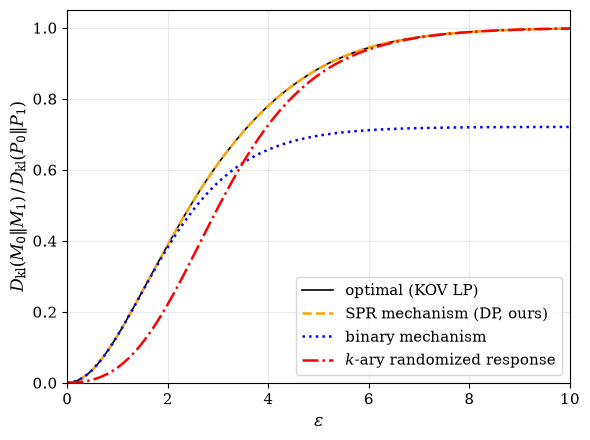

wrote figures/kl_vs_eps_k100_panel.pdf


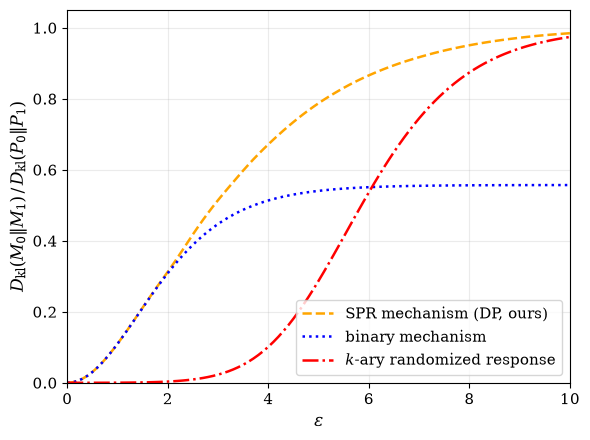

In [5]:
k6.plot(eps6, trials6, str(figures / "kl_vs_eps_k6_panel.pdf"))
plt.show()
k100.plot(eps100, trials100, str(figures / "kl_vs_eps_k100_panel.pdf"))
plt.show()

## 4. Figure 3: pointwise 95% bootstrap confidence intervals

Use 5,000 bootstrap resamples of the trials, with seed 0. The same resampling indices are used across mechanisms. At each privacy value, the interval is given by the 2.5th and 97.5th percentiles of the resampled mean.

wrote figures/kl_vs_eps_k6_panel_with_ci.pdf


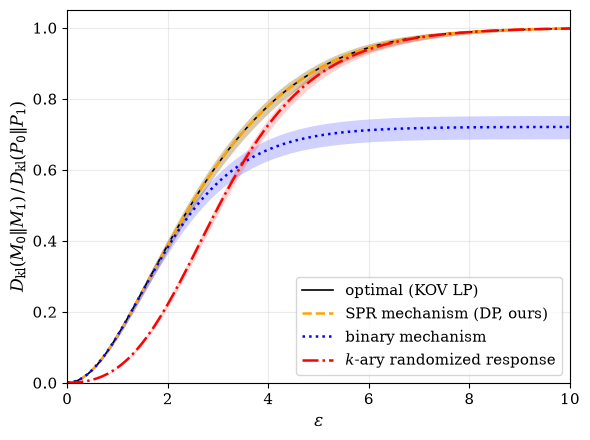

wrote figures/kl_vs_eps_k100_panel_with_ci.pdf


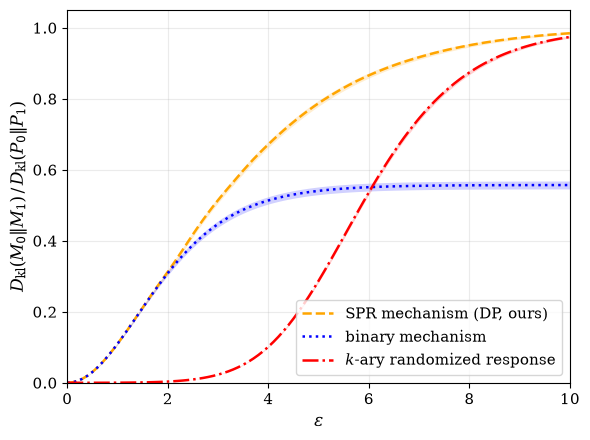

In [6]:
k6.plot_with_ci(eps6, trials6, str(figures / "kl_vs_eps_k6_panel_with_ci.pdf"),
                n_boot=5000, ci_seed=0)
plt.show()
k100.plot_with_ci(eps100, trials100, str(figures / "kl_vs_eps_k100_panel_with_ci.pdf"),
                  n_boot=5000, ci_seed=0)
plt.show()